<a href="https://colab.research.google.com/github/romandudarets/Data-Analysis-University/blob/main/%D0%9B%D1%806_%D0%94%D1%83%D0%B4%D0%B0%D1%80%D0%B5%D1%86%D1%8C_4_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [ ]:
from google.colab import files
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")
uploaded = files.upload()

Saving diabetes_prediction_dataset.csv (1).zip to diabetes_prediction_dataset.csv (1).zip


In [ ]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [ ]:
import kagglehub

path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")
print("Path to dataset files:", path)
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df.head()

100%|██████████| 734k/734k [00:00<00:00, 111MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/iammustafatz/diabetes-prediction-dataset/versions/1


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [ ]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

Вивести інформацію про датасет

In [ ]:
df.info()
print("\nКоментар до типів даних: числові ознаки (age, hypertension, heart_disease, bmi, HbA1c_level, blood_glucose_level, diabetes) мають типи int64/float64, а категоріальні (gender, smoking_history) — object.")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB

Коментар до типів даних: числові ознаки (age, hypertension, heart_disease, bmi, HbA1c_level, blood_glucose_level, diabetes) мають типи int64/float64, а категоріальні (gender, smoking_history) — object.


Провести дослідження категоріальних ознак

In [ ]:
print("Частоти у gender:")
print(df["gender"].value_counts(dropna=False))

Частоти у gender:
gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64


In [ ]:
print("Частоти у smoking_history:")
print(df["smoking_history"].value_counts(dropna=False))

Частоти у smoking_history:
smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64


In [ ]:
print("Частоти у smoking_history:")
print(df["smoking_history"].value_counts(dropna=False))

Частоти у smoking_history:
smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64


Вивести типи даних

In [ ]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Дослідити цільову змінну: перевірити баланс класів

In [ ]:
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Висновок: визначте за результатом, чи є дисбаланс класів.

Перевірити наявність пропущених даних


In [ ]:
print("Баланс класів diabetes:")
print(df["diabetes"].value_counts())
print("\nЧастки класів (%):")
print(df["diabetes"].value_counts(normalize=True) * 100)

Баланс класів diabetes:
diabetes
0    91500
1     8500
Name: count, dtype: int64

Частки класів (%):
diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64


Наявність дублікатів


In [ ]:
print("Пропущені значення:\n", df.isnull().sum())

Пропущені значення:
 gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


Видалити дублікати

In [ ]:
print("Кількість повних дублікатів:", df.duplicated().sum())

Кількість повних дублікатів: 3854


In [ ]:
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print("Розмір після видалення дублікатів:", df.shape)

Розмір після видалення дублікатів: (96146, 9)


Ще раз перевірити баланс цільової змінної

In [ ]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Побудувати гістограму для цільової змінної


In [ ]:
print("Баланс класів diabetes після видалення дублікатів:")
print(df["diabetes"].value_counts())

Баланс класів diabetes після видалення дублікатів:
diabetes
0    87664
1     8482
Name: count, dtype: int64


Переглянути описові статистики **навчальної вибірки**

In [ ]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

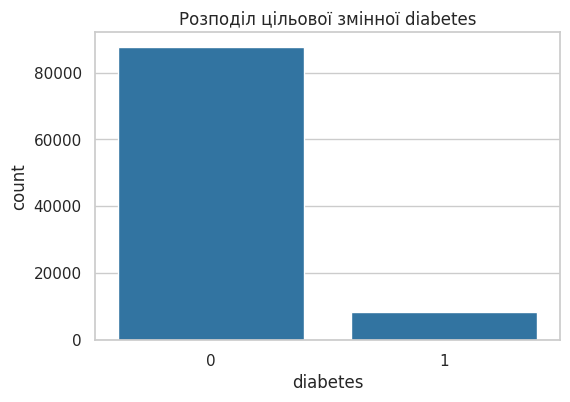

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(x="diabetes", data=df, color="tab:blue")
plt.title("Розподіл цільової змінної diabetes")
plt.show()

Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [ ]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [ ]:
X = df.drop(columns=["diabetes"])
y = df["diabetes"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (76916, 8) | X_test: (19230, 8)


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [ ]:
num_cols = X_train.select_dtypes(include="number").columns
corr_with_y = X_train[num_cols].corrwith(y_train).sort_values(ascending=False)
print("Кореляція числових ознак з y_train:\n", corr_with_y)

Кореляція числових ознак з y_train:
 blood_glucose_level    0.423011
HbA1c_level            0.405321
age                    0.266649
bmi                    0.213456
hypertension           0.199069
heart_disease          0.174470
dtype: float64


In [ ]:
num_train_cols = X_train.select_dtypes(include=[np.number]).columns
corr_matrix_train = X_train[num_train_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix_train, annot=False, cmap="coolwarm", center=0)
plt.title("Матриця кореляцій ознак (X_train)")
plt.tight_layout()
plt.show()

Висновок: найпомітніший позитивний зв'язок із diabetes мають blood_glucose_level, HbA1c_level та age. Сильної мультиколінеарності між ознаками немає, тому видаляти ознаки не потрібно (використання регуляризації у лінійних моделях та ансамблів/SVC достатньо).

Перевірити викиди **лише на навчальній вибірці**

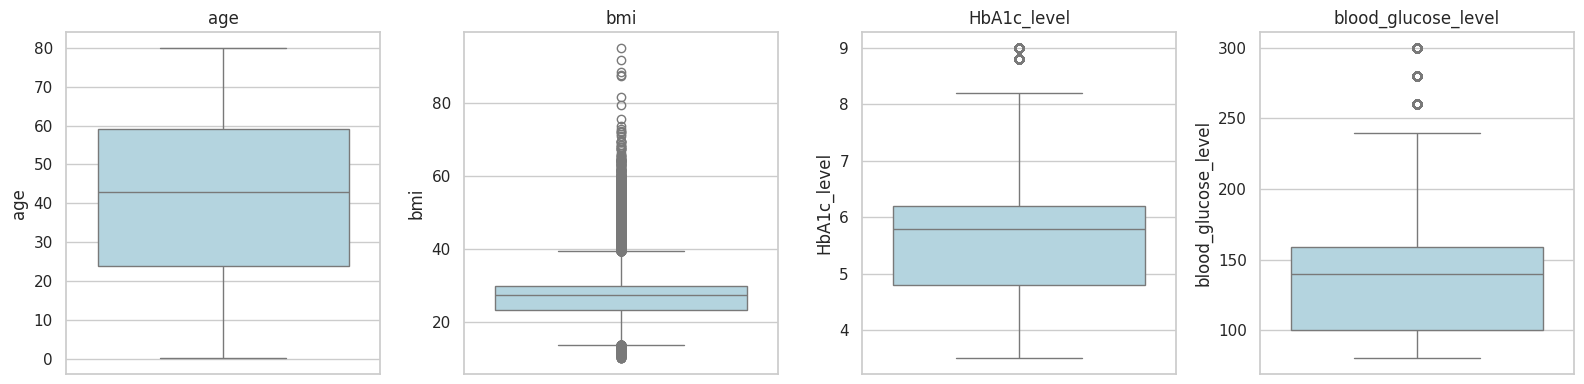

In [ ]:
continuous_cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, continuous_cols):
    sns.boxplot(y=X_train[col], ax=ax, color="lightblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

Висновок: викиди перевіряємо, але в цій лабораторній роботі автоматично не видаляємо. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [ ]:
# НЕОБОВ'ЯЗКОВО (приклад без вилучення рядків):
q1_bmi = X_train["bmi"].quantile(0.25)
q3_bmi = X_train["bmi"].quantile(0.75)
iqr_bmi = q3_bmi - q1_bmi
print(f"BMI IQR на train: {iqr_bmi:.2f}, нижня/верхня межі: {q1_bmi - 1.5*iqr_bmi:.2f} / {q3_bmi + 1.5*iqr_bmi:.2f}")

BMI IQR на train: 6.46, нижня/верхня межі: 13.70 / 39.54


Перевірити асиметрію розподілів ознак **на train**

In [ ]:
print("Коефіцієнти асиметрії (skewness) на X_train[continuous_cols]:")
print(X_train[continuous_cols].skew().sort_values(key=abs, ascending=False))

Коефіцієнти асиметрії (skewness) на X_train[continuous_cols]:
bmi                    1.005016
blood_glucose_level    0.830778
age                   -0.061461
HbA1c_level           -0.055651
dtype: float64


In [ ]:
print("Пропуски в X_train:", X_train.isna().sum().sum())
print("Пропуски в X_test: ", X_test.isna().sum().sum())

Пропуски в X_train: 0
Пропуски в X_test:  0


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [ ]:
cat_cols = [c for c in ["gender", "smoking_history"] if c in X_train.columns]
if cat_cols:
    X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=False, dtype=int)
    X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=False, dtype=int)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [ ]:
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

# На всякий случай кодируем категоріальні ознаки, якщо вони ще не закодовані
cat_cols = [c for c in ["gender", "smoking_history"] if c in X_train.columns]
if cat_cols:
    X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=False, dtype=int)
    X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=False, dtype=int)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

print("До SMOTE:", y_train.value_counts().to_dict())
print("Після SMOTE:", pd.Series(y_train_bal).value_counts().to_dict())

До SMOTE: {0: 70130, 1: 6786}
Після SMOTE: {0: 70130, 1: 70130}


Оголошуємо моделі

In [ ]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC

models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
    "RidgeClassifier": RidgeClassifier(random_state=42),
    "SGDClassifier": SGDClassifier(random_state=42),
    "SVC": SVC(probability=True, random_state=42),
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт


=== LogisticRegression ===
              precision    recall  f1-score   support

           0     0.9870    0.8854    0.9334     17534
           1     0.4260    0.8791    0.5739      1696

    accuracy                         0.8849     19230
   macro avg     0.7065    0.8823    0.7537     19230
weighted avg     0.9375    0.8849    0.9017     19230



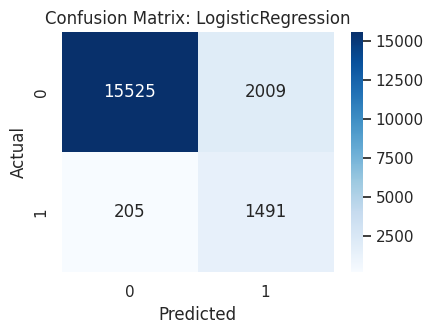

=== RidgeClassifier ===
              precision    recall  f1-score   support

           0     0.9866    0.8889    0.9352     17534
           1     0.4324    0.8750    0.5788      1696

    accuracy                         0.8877     19230
   macro avg     0.7095    0.8820    0.7570     19230
weighted avg     0.9377    0.8877    0.9038     19230



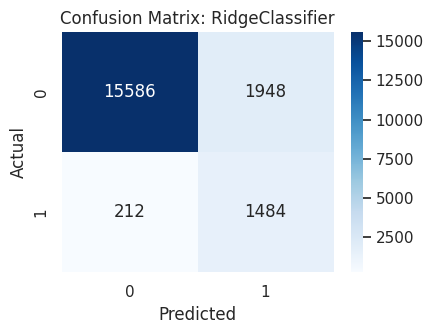

=== SGDClassifier ===
              precision    recall  f1-score   support

           0     0.9898    0.8563    0.9182     17534
           1     0.3796    0.9086    0.5354      1696

    accuracy                         0.8609     19230
   macro avg     0.6847    0.8825    0.7268     19230
weighted avg     0.9360    0.8609    0.8845     19230



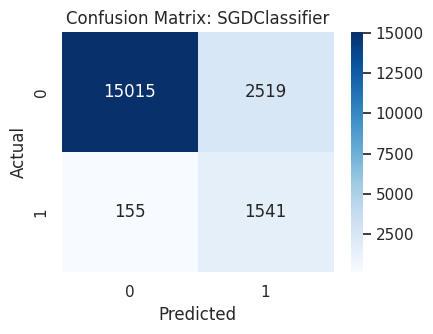

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

for name, clf in models.items():
    clf.fit(X_train_bal, y_train_bal)
    y_pred = clf.predict(X_test_scaled)

    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred, digits=4))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4.5, 3.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

Оптимізувати гіперпараметри


In [ ]:
param_grids = {
    "LogisticRegression": {
        "clf__C": [0.1, 1.0, 10.0],
        "clf__solver": ["lbfgs", "liblinear"],
    },
    "RidgeClassifier": {
        "clf__alpha": [0.1, 1.0, 10.0],
    },
    "SGDClassifier": {
        "clf__loss": ["log_loss", "hinge"],
        "clf__penalty": ["l2", "elasticnet"],
        "clf__alpha": [1e-4, 1e-3],
    },
    "SVC": {
        "clf__C": [0.5, 1.0, 5.0],
        "clf__kernel": ["rbf", "linear"],
    },
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [ ]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [ ]:
best_models = {}
best_scores = {}

base_estimators = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
    "RidgeClassifier": RidgeClassifier(random_state=42),
    "SGDClassifier": SGDClassifier(random_state=42),
    "SVC": SVC(probability=True, random_state=42),
}

for name, est in base_estimators.items():
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("clf", est),
    ])

    search = HalvingGridSearchCV(
        estimator=pipe,
        param_grid=param_grids[name],
        cv=3,
        scoring="f1",
        min_resources=300,
        random_state=42,
        n_jobs=-1,
    )
    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    y_pred_best = best_models[name].predict(X_test)
    print(f"--- {name} ---")
    print("Найкращі параметри:", search.best_params_)
    print(f"Середній F1 на CV (cv=3): {search.best_score_:.4f}")
    print(classification_report(y_test, y_pred_best, digits=4))

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [ ]:
best_model_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_model_name]

print(f"Найкраща модель за кросвалідацією: {best_model_name} (CV F1 = {best_scores[best_model_name]:.4f})")

In [ ]:
sample_test = X_test.sample(n=10, random_state=42)
sample_true = y_test.loc[sample_test.index]
sample_pred = best_model.predict(sample_test)

pred_table = pd.DataFrame({
    "index": sample_test.index,
    "actual_diabetes": sample_true.values,
    "predicted_diabetes": sample_pred,
})
display(pred_table)

NameError: name 'best_model' is not defined

Підсумкові висновки:

У датасеті спостерігався сильний дисбаланс класів (клас 1 становить меншість); аналіз на train показав найвагоміший зв'язок рівня глюкози та HbA1c_level із цільовою змінною, а екстремальні значення збережено без видалення, щоб не втратити клінічно важливі випадки.

Балансування через SMOTE підвищує повноту (recall) та F1 для класу diabetes = 1 порівняно з наївним прогнозом більшості класу 0; фінальна модель обирається виключно за середнім F1 на крос-валідації (cv=3).

Підбір гіперпараметрів через HalvingGridSearchCV дає змогу знайти компроміс між хибнопозитивними (FP) та хибнонегативними (FN) помилками у матриці плутанини.

Тестову вибірку відкладають і не балансують, а StandardScaler та SMOTE виконують лише на навчальних даних / всередині Pipeline на кожному згині, щоб уникнути витоку даних та отримати чесну оцінку якості на нових даних.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики